[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pantrok/hidroxai-mx/blob/main/notebooks/tutoriales/04_explicaciones.ipynb)

# Tutorial 4 · Explicaciones de los pronósticos

**Objetivo.** atribuir cada pronóstico a los días y variables de su ventana con TreeSHAP (XGBoost) e Integrated Gradients (TCN), dibujar el mapa variable × día y comparar dos semillas del mismo modelo para ver cuánto acuerdo cabe esperar (techo de ruido).

> Las cifras son ilustrativas. Los resultados del benchmark están en [`results/xai_benchmark/`](https://github.com/pantrok/hidroxai-mx/tree/xai-benchmark-v1.5/results/xai_benchmark) (archivos `rq2_*`).

*Proyecto IND-2026-0335 · Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.*

In [1]:
# En Colab instala la biblioteca desde GitHub; fuera de Colab usa la que ya esté instalada.
# Va sin dependencias porque Colab ya trae pandas, pyarrow, matplotlib, torch y xgboost.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("hidroxai_mx") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                    "git+https://github.com/pantrok/hidroxai-mx@main"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "captum"], check=True)

## 1. Datos y modelos

`E.entrenar` repite los pasos del tutorial 3 (misma cuenca, horizonte de 1 día) para XGBoost y la TCN con dos semillas.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hidroxai_mx import ejemplos as E
from hidroxai_mx.dataset import abrir_dataset, como_citar
from hidroxai_mx.models import xgb as X
from hidroxai_mx.xai import attributions as A

REDUCIDO = E.modo_reducido()           # modo rápido para la integración continua
ds = abrir_dataset()
claves = E.claves_cuenca(ds.vinculo_hidrorivers(), E.CUENCA)
if REDUCIDO:
    claves = claves[:3]
paneles = E.paneles(ds.tabla_caracteristicas(claves=claves), claves)
res = E.entrenar(paneles, h=1)
te = res["arr"]["test"]
print(f"{len(paneles)} estaciones; {len(te['y']):,} ventanas de prueba; modelos: {sorted(res['pronosticos'])}")

12 estaciones; 6,710 ventanas de prueba; modelos: ['tcn_s20261010', 'tcn_s20261011', 'xgboost_s20261010', 'xgboost_s20261011']


## 2. Atribuciones

Se explica una muestra de ventanas de prueba con el mismo número por estación. TreeSHAP es exacto para árboles; Integrated Gradients integra el gradiente desde una ventana de ceros y reporta su error de completitud. La importancia de cada día y canal es el valor absoluto de la atribución, normalizado a suma 1 por ventana y promediado.

In [3]:
idx = A.stratified_sample(te["meta"], n_max=200 if REDUCIDO else 500)
Xs = te["X"][idx]
importancias = {}
for (modelo, semilla), obj in res["modelos"].items():
    if modelo == "xgboost":
        attr = X.tree_shap(obj, Xs)
    else:
        attr, delta = A.integrated_gradients(obj, Xs, n_steps=32 if REDUCIDO else 64)
        print(f"IG {modelo} semilla {semilla}: error de completitud mediano {np.median(np.abs(delta)):.1e}")
    importancias[f"{modelo}_s{semilla}"] = A.importance(attr)        # [30 días, 6 canales]
print(f"{len(idx)} ventanas explicadas")

IG tcn semilla 20261010: error de completitud mediano 1.0e-03


IG tcn semilla 20261011: error de completitud mediano 1.1e-03
500 ventanas explicadas


## 3. Mapa variable × día

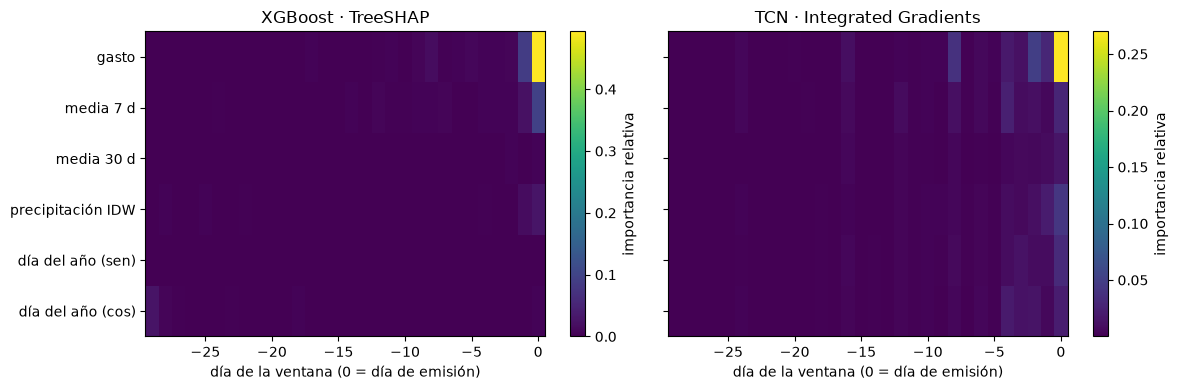

In [4]:
NOMBRES = ["gasto", "media 7 d", "media 30 d", "precipitación IDW",
           "día del año (sen)", "día del año (cos)"]
s1 = E.SEMILLAS[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, modelo, titulo in [(axes[0], "xgboost", "XGBoost · TreeSHAP"),
                           (axes[1], "tcn", "TCN · Integrated Gradients")]:
    im = ax.imshow(importancias[f"{modelo}_s{s1}"].T, aspect="auto", cmap="viridis",
                   extent=[-29.5, 0.5, 5.5, -0.5])
    ax.set_yticks(range(6), NOMBRES)
    ax.set_xlabel("día de la ventana (0 = día de emisión)")
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, label="importancia relativa")
plt.tight_layout()
plt.show()

Importancia total de cada canal (suma sobre los 30 días):

In [5]:
pd.DataFrame({k: v.sum(axis=0) for k, v in importancias.items()}, index=NOMBRES).round(3)

,xgboost_s20261010,tcn_s20261010,xgboost_s20261011,tcn_s20261011
gasto,0.661,0.460,0.675,0.443
media 7 d,0.177,0.127,0.127,0.093
media 30 d,0.017,0.069,0.034,0.137
precipitación IDW,0.072,0.125,0.087,0.120
día del año (sen),0.007,0.109,0.009,0.114
día del año (cos),0.066,0.109,0.068,0.092


## 4. Dos semillas: el techo de ruido

El mismo modelo entrenado con otra semilla no da exactamente las mismas explicaciones. La correlación de Spearman entre sus mapas es un techo: el acuerdo entre dos modelos distintos solo es informativo si se compara con él.

In [6]:
conc = A.concordance(importancias)
misma = conc["modelo_a"].str.split("_").str[0] == conc["modelo_b"].str.split("_").str[0]
conc["comparación"] = np.where(misma, "misma arquitectura, otra semilla", "entre arquitecturas")
conc.round(3)

,modelo_a,modelo_b,spearman,comparación
0,tcn_s20261010,tcn_s20261011,0.952,"misma arquitectura, otra semilla"
1,tcn_s20261010,xgboost_s20261010,0.218,entre arquitecturas
2,tcn_s20261010,xgboost_s20261011,0.217,entre arquitecturas
3,tcn_s20261011,xgboost_s20261010,0.230,entre arquitecturas
4,tcn_s20261011,xgboost_s20261011,0.228,entre arquitecturas
5,xgboost_s20261010,xgboost_s20261011,0.702,"misma arquitectura, otra semilla"


## Cómo citar

Si usas estos datos, cita el artículo que describe el dataset (*Data in Brief*, 2026) y la versión del dataset que usaste. Las referencias salen de los metadatos de Crossref y de Zenodo.

In [7]:
print(como_citar())

Artículo de datos:
Sánchez-Ruiz, D., Reyes-Peña, C., Reyes-Cocoletzi, L., García-Ramírez, J., Ramos-Aguilar, E., & Ramos-Aguilar, R. (2026). Hidro-MX: daily hydroclimatic dataset for four pilot basins in Mexico from National Water Commission and National Institute of Statistics and Geography sources, with digital elevation models and station–river network links. Data in Brief, 69, 113442. https://doi.org/10.1016/j.dib.2026.113442

Dataset (v2026.11):
Sánchez-Ruiz, D., Ramos Aguilar, E., Ramos-Aguilar, R., Reyes-Peña, C., Reyes-Cocoletzi, L., & García-Ramírez, J. (2026). Hidro-MX v2026.11: a reproducible hydroclimatic dataset for Mexican pilot basins (CONAGUA-SIH and INEGI) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.24119292
Todas las versiones (DOI de concepto): https://doi.org/10.5281/zenodo.21231600

Créditos: Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026 · proyecto IND-2026-0335. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.
